## KECERDASAN ARTIFISIAL UNTUK GEOFISIKA
## PEMBUATAN RECIPE

### Analisis Data Curah Hujan Makassar Menggunakan Python

**Nama:** Gladiva Warouw
**NIM:** H061241061
**Kelas:** B

# Pengolahan Data Curah Hujan Makassar Menggunakan Python

**Jenis data:** data curah hujan harian dari Open-Meteo Historical Weather API.  
**Wilayah kajian:** Makassar, Sulawesi Selatan (sekitar lintang -5,1477° dan bujur 119,4327°).  
**Periode:** 1 Januari 2016–31 Desember 2025.  
**Variabel utama:** presipitasi harian, dalam milimeter (mm).

> **Catatan penting:** data yang diambil melalui API ini merupakan data cuaca historis berbasis grid/model, bukan pengukuran langsung dari stasiun hujan tertentu. Untuk penelitian resmi, cocokkan dengan data observasi BMKG jika tersedia.

## Recipe workflow

**Problem → Teori Minimal → Rencana → Kode → Hasil → Pemeriksaan**

Analisis ini merangkum curah hujan harian menjadi statistik tahunan dan bulanan, memeriksa nilai yang hilang atau tidak masuk akal, serta membuat grafik untuk melihat variasi curah hujan dari waktu ke waktu. Analisis ini bersifat deskriptif, bukan prakiraan cuaca atau analisis penyebab hujan.

## 1. Teori singkat dan sumber data

Presipitasi harian menunjukkan jumlah air yang jatuh sebagai hujan dan presipitasi lainnya selama satu hari, dinyatakan dalam milimeter (mm). Penjumlahan nilai harian dapat digunakan untuk memperoleh total presipitasi per bulan atau tahun selama semua hari yang diperlukan tersedia.

Sumber data:
- Open-Meteo Historical Weather API: https://open-meteo.com/en/docs/historical-weather-api
- API archive: https://archive-api.open-meteo.com/v1/archive

**Batasan interpretasi:** nilai grid dapat berbeda dari pengukuran penakar hujan di lapangan karena perbedaan resolusi spasial, metode estimasi, dan kondisi setempat. Nilai kosong tidak otomatis dianggap nol.

## 2. Atur parameter dan pustaka

Jalankan sel berikut untuk memuat pustaka dan menetapkan wilayah, periode, serta folder keluaran.

In [11]:
from pathlib import Path
import time
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Parameter analisis
PARAMS = {
    "latitude": -5.1477,
    "longitude": 119.4327,
    "location_name": "Makassar, Sulawesi Selatan",
    "start_date": "2016-01-01",
    "end_date": "2025-12-31",
    "timezone": "Asia/Makassar",
    "precipitation_variable": "precipitation_sum"
}

OUT_DIR = Path("results")
FIG_DIR = Path("figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Parameter analisis:")
display(pd.Series(PARAMS, name="Nilai").to_frame())

Parameter analisis:


,Nilai
latitude,-5.1477
longitude,119.4327
location_name,"Makassar, Sulawesi Selatan"
start_date,2016-01-01
end_date,2025-12-31
timezone,Asia/Makassar
precipitation_variable,precipitation_sum


## 3. Unduh data historis

Sel ini meminta data harian dari Open-Meteo. Koneksi internet diperlukan. Jika unduhan gagal, periksa koneksi dan pesan kesalahan; notebook tidak mengganti data aktual dengan angka buatan.

In [12]:
API_URL = "https://archive-api.open-meteo.com/v1/archive"
request_params = {
    "latitude": PARAMS["latitude"],
    "longitude": PARAMS["longitude"],
    "start_date": PARAMS["start_date"],
    "end_date": PARAMS["end_date"],
    "daily": PARAMS["precipitation_variable"],
    "timezone": PARAMS["timezone"]
}

response = requests.get(API_URL, params=request_params, timeout=90)
response.raise_for_status()
payload = response.json()

if "daily" not in payload or "time" not in payload["daily"]:
    raise ValueError(f"Respons API tidak berisi data harian yang diharapkan: {payload}")

df_raw = pd.DataFrame({
    "date": payload["daily"]["time"],
    "precipitation_mm": payload["daily"][PARAMS["precipitation_variable"]]
})
df_raw["date"] = pd.to_datetime(df_raw["date"], errors="coerce")
raw_path = OUT_DIR / "curah_hujan_makassar_raw.csv"
df_raw.to_csv(raw_path, index=False)

print(f"Data berhasil diunduh: {len(df_raw)} baris")
print(f"CSV mentah disimpan ke: {raw_path}")
display(df_raw.head())

Data berhasil diunduh: 3653 baris
CSV mentah disimpan ke: results\curah_hujan_makassar_raw.csv


,date,precipitation_mm
0,2016-01-01,2.3
1,2016-01-02,2.5
2,2016-01-03,0.8
3,2016-01-04,3.6
4,2016-01-05,2.7


## 4. Pahami kolom dan lakukan QA/QC

Pemeriksaan kualitas data (QA/QC) meliputi:
- tanggal yang tidak valid atau duplikat;
- nilai presipitasi yang kosong;
- nilai presipitasi negatif;
- tanggal di luar periode analisis.

Data mentah tetap disimpan. Catatan bermasalah ditandai agar dapat ditinjau, bukan dihapus secara diam-diam.

In [13]:
df = df_raw.copy()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["precipitation_mm"] = pd.to_numeric(df["precipitation_mm"], errors="coerce")

df["qc_flag"] = ""
df.loc[df["date"].isna(), "qc_flag"] += "tanggal_tidak_valid;"
df.loc[df["precipitation_mm"].isna(), "qc_flag"] += "presipitasi_kosong;"
df.loc[df["precipitation_mm"] < 0, "qc_flag"] += "presipitasi_negatif;"
df.loc[df["date"].duplicated(keep=False) & df["date"].notna(), "qc_flag"] += "tanggal_duplikat;"

start = pd.Timestamp(PARAMS["start_date"])
end = pd.Timestamp(PARAMS["end_date"])
outside = df["date"].notna() & ~df["date"].between(start, end)
df.loc[outside, "qc_flag"] += "tanggal_di_luar_periode;"

df["qc_status"] = np.where(df["qc_flag"].eq(""), "OK", "REVIEW")
qc_path = OUT_DIR / "curah_hujan_makassar_qc.csv"
df.to_csv(qc_path, index=False)

qc_report = {
    "jumlah_baris_awal": int(len(df)),
    "tanggal_tidak_valid": int(df["date"].isna().sum()),
    "presipitasi_kosong": int(df["precipitation_mm"].isna().sum()),
    "presipitasi_negatif": int((df["precipitation_mm"] < 0).sum()),
    "tanggal_duplikat": int(df.loc[df["date"].notna(), "date"].duplicated(keep=False).sum()),
    "baris_ditandai_review": int((df["qc_status"] == "REVIEW").sum())
}
display(pd.Series(qc_report, name="Jumlah").to_frame())
print("Berkas QA/QC:", qc_path)

,Jumlah
jumlah_baris_awal,3653
tanggal_tidak_valid,0
presipitasi_kosong,0
presipitasi_negatif,0
tanggal_duplikat,0
baris_ditandai_review,0


Berkas QA/QC: results\curah_hujan_makassar_qc.csv


## 5. Siapkan data untuk analisis

Untuk statistik utama, digunakan tanggal yang valid, tanggal unik, nilai presipitasi tidak kosong, dan nilai presipitasi tidak negatif. Nilai kosong tidak diubah menjadi nol. Periksa jumlah hari yang tersedia sebelum menafsirkan total bulanan atau tahunan.

In [14]:
df_valid = df.loc[
    df["date"].notna()
    & df["precipitation_mm"].notna()
    & (df["precipitation_mm"] >= 0)
    & ~df["date"].duplicated(keep="first")
    & df["date"].between(start, end)
].copy()

if df_valid.empty:
    raise ValueError("Tidak ada data valid setelah QA/QC. Periksa respons API dan parameter.")

df_valid["year"] = df_valid["date"].dt.year
df_valid["month"] = df_valid["date"].dt.month
df_valid["year_month"] = df_valid["date"].dt.to_period("M").astype(str)

print("Jumlah baris awal:", len(df))
print("Jumlah baris valid untuk analisis:", len(df_valid))
print("Rentang tanggal:", df_valid["date"].min(), "sampai", df_valid["date"].max())
display(df_valid.head())

Jumlah baris awal: 3653
Jumlah baris valid untuk analisis: 3653
Rentang tanggal: 2016-01-01 00:00:00 sampai 2025-12-31 00:00:00


,date,precipitation_mm,qc_flag,qc_status,year,month,year_month
0,2016-01-01,2.3,,OK,2016,1,2016-01
1,2016-01-02,2.5,,OK,2016,1,2016-01
2,2016-01-03,0.8,,OK,2016,1,2016-01
3,2016-01-04,3.6,,OK,2016,1,2016-01
4,2016-01-05,2.7,,OK,2016,1,2016-01


## 6. Ringkasan statistik

Ringkasan statistik menggambarkan sebaran presipitasi harian pada data yang tersedia. Nilai rata-rata dan maksimum tidak menjelaskan sendiri risiko banjir atau kondisi hidrologi karena dampak juga dipengaruhi durasi hujan, drainase, topografi, penggunaan lahan, dan faktor lain.

In [15]:
summary = df_valid["precipitation_mm"].describe().to_frame(name="presipitasi_harian_mm")
display(summary)

print("Total presipitasi dari baris valid (mm):", round(df_valid["precipitation_mm"].sum(), 2))
print("Rata-rata harian (mm):", round(df_valid["precipitation_mm"].mean(), 2))
print("Presipitasi harian maksimum (mm):", round(df_valid["precipitation_mm"].max(), 2))

,presipitasi_harian_mm
count,3653.000000
mean,7.215905
std,10.974708
min,0.000000
25%,0.300000
50%,2.700000
75%,10.000000
max,112.600000


Total presipitasi dari baris valid (mm): 26359.7
Rata-rata harian (mm): 7.22
Presipitasi harian maksimum (mm): 112.6


## 7. Analisis presipitasi tahunan

Total tahunan dihitung dengan menjumlahkan nilai harian yang tersedia pada setiap tahun. Jumlah hari valid juga ditampilkan agar total antar-tahun dapat dibaca dengan hati-hati ketika kelengkapan data berbeda.

,year,total_presipitasi_mm,rata_rata_harian_mm,maksimum_harian_mm,jumlah_hari_valid
0,2016,3217.7,8.791530,65.2,366
1,2017,2899.2,7.943014,112.6,365
2,2018,2576.0,7.057534,59.8,365
3,2019,1950.4,5.343562,102.1,365
4,2020,2639.5,7.211749,76.4,366
5,2021,2960.6,8.111233,72.2,365
6,2022,3217.3,8.814521,86.2,365
7,2023,1939.6,5.313973,68.3,365
8,2024,2575.8,7.037705,100.7,366
9,2025,2383.6,6.530411,50.8,365


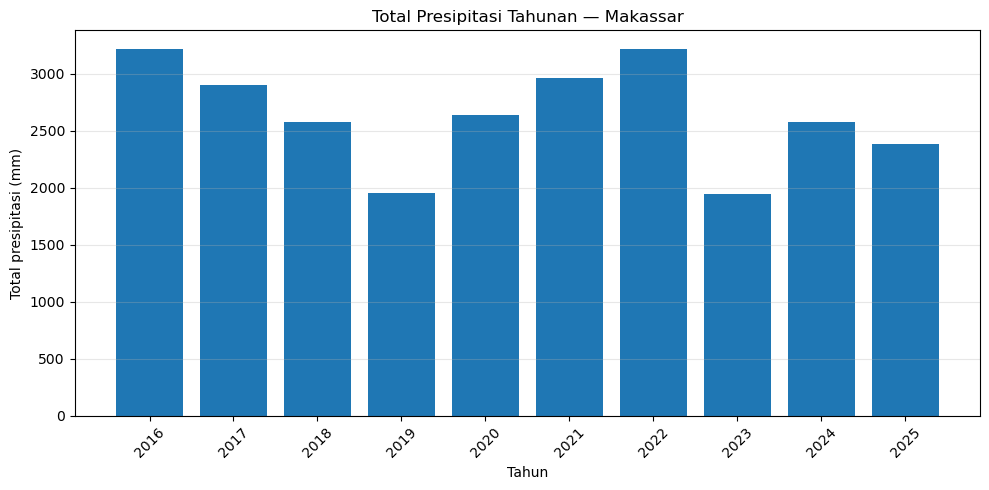

In [16]:
annual_summary = (
    df_valid.groupby("year")
    .agg(
        total_presipitasi_mm=("precipitation_mm", "sum"),
        rata_rata_harian_mm=("precipitation_mm", "mean"),
        maksimum_harian_mm=("precipitation_mm", "max"),
        jumlah_hari_valid=("date", "count")
    )
    .reset_index()
)
display(annual_summary)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(annual_summary["year"].astype(str), annual_summary["total_presipitasi_mm"])
ax.set_title("Total Presipitasi Tahunan — Makassar")
ax.set_xlabel("Tahun")
ax.set_ylabel("Total presipitasi (mm)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
annual_fig = FIG_DIR / "total_presipitasi_tahunan.png"
fig.savefig(annual_fig, dpi=160, bbox_inches="tight")
plt.show()

## 8. Pola bulanan dan klimatologi sederhana

Grafik bulanan menunjukkan total presipitasi untuk setiap bulan pada rentang data. Rata-rata klimatologi bulanan dihitung dengan merata-ratakan total bulanan untuk bulan kalender yang sama sepanjang tahun yang tersedia. Ini merupakan ringkasan deskriptif, bukan prediksi untuk tahun berikutnya.

,year,month,total_presipitasi_mm,jumlah_hari_valid,year_month
0,2016,1,234.5,31,2016-01
1,2016,2,340.5,29,2016-02
2,2016,3,278.6,31,2016-03
3,2016,4,394.5,30,2016-04
4,2016,5,248.1,31,2016-05
5,2016,6,246.4,30,2016-06
6,2016,7,195.9,31,2016-07
7,2016,8,58.9,31,2016-08
8,2016,9,156.8,30,2016-09
9,2016,10,463.8,31,2016-10


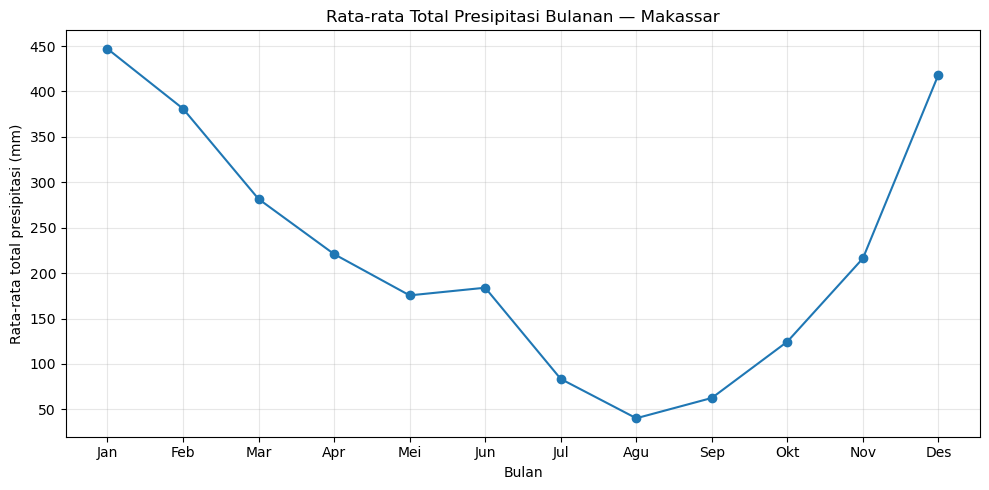

In [17]:
monthly_summary = (
    df_valid.groupby(["year", "month"])
    .agg(
        total_presipitasi_mm=("precipitation_mm", "sum"),
        jumlah_hari_valid=("date", "count")
    )
    .reset_index()
)
monthly_summary["year_month"] = (
    monthly_summary["year"].astype(str) + "-" +
    monthly_summary["month"].astype(str).str.zfill(2)
)
display(monthly_summary.head(12))

monthly_climatology = (
    monthly_summary.groupby("month")["total_presipitasi_mm"]
    .mean()
    .reindex(range(1, 13))
)
month_names = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
               "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(month_names, monthly_climatology.values, marker="o")
ax.set_title("Rata-rata Total Presipitasi Bulanan — Makassar")
ax.set_xlabel("Bulan")
ax.set_ylabel("Rata-rata total presipitasi (mm)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
monthly_fig = FIG_DIR / "klimatologi_presipitasi_bulanan.png"
fig.savefig(monthly_fig, dpi=160, bbox_inches="tight")
plt.show()

## 9. Grafik deret waktu harian

Grafik ini memperlihatkan perubahan nilai presipitasi harian sepanjang periode kajian. Grafik padat dapat terlihat bergerigi; untuk melihat pola jangka panjang, gunakan ringkasan bulanan atau tahunan pada bagian sebelumnya.

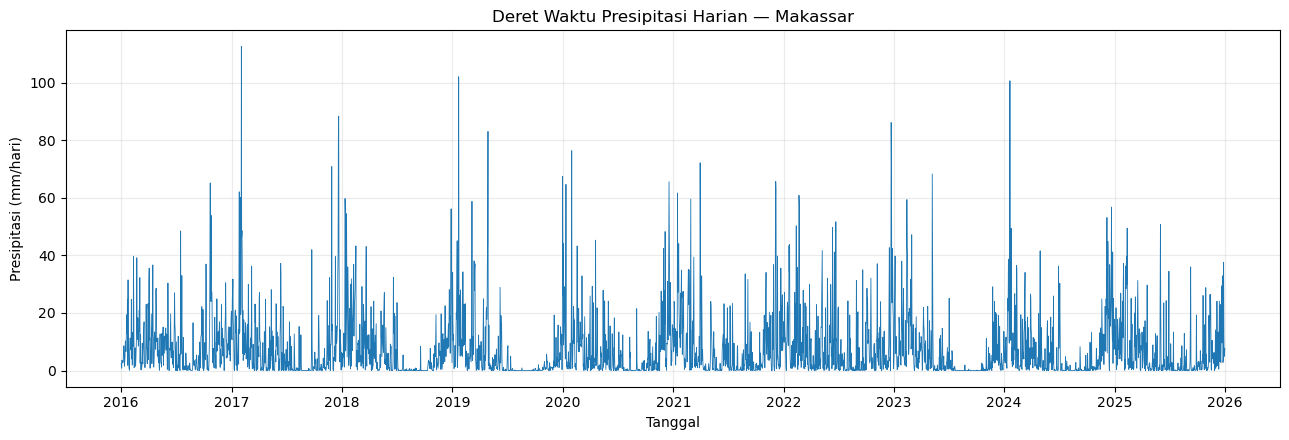

In [18]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(df_valid["date"], df_valid["precipitation_mm"], linewidth=0.6)
ax.set_title("Deret Waktu Presipitasi Harian — Makassar")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Presipitasi (mm/hari)")
ax.grid(True, alpha=0.25)
plt.tight_layout()
daily_fig = FIG_DIR / "deret_waktu_presipitasi_harian.png"
fig.savefig(daily_fig, dpi=160, bbox_inches="tight")
plt.show()

## 10. Simpan hasil olahan dan catatan proses

Notebook menyimpan data mentah, data dengan penanda QA/QC, data valid, ringkasan tahunan, ringkasan bulanan, dan catatan parameter. Catatan ini membantu pembaca menelusuri sumber serta konfigurasi yang digunakan.

In [19]:
clean_path = OUT_DIR / "curah_hujan_makassar_valid.csv"
annual_path = OUT_DIR / "ringkasan_presipitasi_tahunan.csv"
monthly_path = OUT_DIR / "ringkasan_presipitasi_bulanan.csv"
climatology_path = OUT_DIR / "klimatologi_presipitasi_bulanan.csv"
qc_report_path = OUT_DIR / "laporan_qc.json"
run_record_path = OUT_DIR / "run_record.json"

df_valid.to_csv(clean_path, index=False)
annual_summary.to_csv(annual_path, index=False)
monthly_summary.to_csv(monthly_path, index=False)
monthly_climatology.rename_axis("month").rename("rata_rata_total_presipitasi_mm").reset_index().to_csv(
    climatology_path, index=False
)

with open(qc_report_path, "w", encoding="utf-8") as f:
    json.dump(qc_report, f, indent=2, ensure_ascii=False)

run_record = {
    "recipe_id": "R-RAIN-002",
    "judul": "Analisis data curah hujan Makassar",
    "sumber": "Open-Meteo Historical Weather API",
    "api_url": response.url,
    "parameter": PARAMS,
    "jumlah_baris_mentah": int(len(df_raw)),
    "jumlah_baris_valid": int(len(df_valid)),
    "catatan": "Data historis berbasis grid/model; bukan pengamatan langsung stasiun hujan."
}
with open(run_record_path, "w", encoding="utf-8") as f:
    json.dump(run_record, f, indent=2, ensure_ascii=False)

print("Hasil tersimpan:")
for p in [raw_path, qc_path, clean_path, annual_path, monthly_path,
          climatology_path, qc_report_path, run_record_path,
          annual_fig, monthly_fig, daily_fig]:
    print("-", p)

Hasil tersimpan:
- results\curah_hujan_makassar_raw.csv
- results\curah_hujan_makassar_qc.csv
- results\curah_hujan_makassar_valid.csv
- results\ringkasan_presipitasi_tahunan.csv
- results\ringkasan_presipitasi_bulanan.csv
- results\klimatologi_presipitasi_bulanan.csv
- results\laporan_qc.json
- results\run_record.json
- figures\total_presipitasi_tahunan.png
- figures\klimatologi_presipitasi_bulanan.png
- figures\deret_waktu_presipitasi_harian.png


## 11. Pemeriksaan akhir

Pemeriksaan berikut memastikan tabel valid tidak kosong, tanggal unik, nilai presipitasi tidak negatif, serta jumlah baris pada berkas QA/QC sama dengan jumlah data mentah. Ini adalah pemeriksaan konsistensi dasar, bukan validasi independen terhadap pengamatan BMKG.

In [20]:
assert not df_valid.empty, "Data valid kosong"
assert df_valid["date"].notna().all(), "Masih ada tanggal tidak valid"
assert not df_valid["date"].duplicated().any(), "Masih ada tanggal duplikat"
assert df_valid["precipitation_mm"].notna().all(), "Masih ada presipitasi kosong"
assert (df_valid["precipitation_mm"] >= 0).all(), "Ada presipitasi negatif"
assert len(df) == len(df_raw), "Jumlah baris QA/QC berubah dari data mentah"
assert annual_summary["year"].notna().all(), "Tahun ringkasan tidak valid"

print("Pemeriksaan konsistensi dasar: LULUS")
print("Ingat: hasil berlaku untuk lokasi, periode, sumber, dan versi data yang digunakan.")

Pemeriksaan konsistensi dasar: LULUS
Ingat: hasil berlaku untuk lokasi, periode, sumber, dan versi data yang digunakan.


## 12. Keterbatasan

1. Data API berbasis grid/model dan tidak selalu sama dengan pengukuran stasiun.
2. Analisis hanya mewakili satu titik koordinat di Makassar, bukan seluruh wilayah Sulawesi Selatan.
3. Total bulanan/tahunan dapat bias jika ada hari yang hilang; perhatikan `jumlah_hari_valid`.
4. Korelasi atau pola musiman tidak membuktikan hubungan sebab-akibat.
5. Untuk analisis ilmiah lanjutan, bandingkan dengan data stasiun resmi, dokumentasikan versi data, dan pertimbangkan ketidakpastian sumber.